In [1]:
import pickle
import numpy as np

# Load preprocessed EEG data
pkl_path = r"C:\Users\rajab\Desktop\FACED dataset\Processed_data\Processed_data\sub000.pkl"

with open(pkl_path, 'rb') as f:
    eeg_data = pickle.load(f)

print("EEG data shape:", eeg_data.shape)


EEG data shape: (28, 32, 7500)


In [ ]:
import hdf5storage

mat_path = r"C:\Users\rajab\Desktop\FACED dataset\Data\Data\sub000\After_remarks.mat"
remark = hdf5storage.loadmat(mat_path)

In [4]:
import hdf5storage

mat_path = r"C:\Users\rajab\Desktop\FACED dataset\Data\Data\sub000\After_remarks.mat"
remark = hdf5storage.loadmat(mat_path)

# Explore keys
print("Keys in .mat file:", remark.keys())

# Try accessing the main object
after_remark = remark['After_remark']

# Check its fields (structure)
print("Fields in After_remark:", after_remark.dtype)


Keys in .mat file: dict_keys(['__header__', '__version__', '__globals__', 'After_remark'])
Fields in After_remark: [('score', 'O'), ('trial', 'O'), ('vid', 'O'), ('Accuracy', 'O'), ('ResponseTime', 'O')]


In [21]:
# Extract all scores and video IDs
raw_scores = after_remark['score'].squeeze()     # shape: (28,)
raw_vids = after_remark['vid'].squeeze()         # shape: (28,)

# Flatten scores and vids
scores = np.array([s.squeeze() for s in raw_scores])        # shape: (28, 12)
vids = np.array([v.squeeze() for v in raw_vids])            # shape: (28,)

# Sort indices based on vid
sorted_idx = np.argsort(vids)

# Sort EEG and labels based on vid order
eeg_data_sorted = eeg_data[sorted_idx]
labels = np.argmax(scores[sorted_idx, :8], axis=1)  # only top-8 emotion scores

print("eeg_data_sorted shape:", eeg_data_sorted.shape)
print("labels shape:", labels.shape)
print("labels:", labels)


eeg_data_sorted shape: (28, 32, 7500)
labels shape: (28,)
labels: [4 4 4 5 5 5 6 6 3 7 7 1 1 6 7 1 3 3 3 2 2 2 1 0 0 1 1 1]


In [22]:
import torch
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

class EEGDataset(Dataset):
    def __init__(self, data, labels, scaler=None):
        # data shape: (N, C, T) → we reshape to (N, T, C)
        self.data = data.transpose(0, 2, 1)  # (N, T, C)

        # normalize per-channel across all time steps
        N, T, C = self.data.shape
        reshaped = self.data.reshape(-1, C)  # (N*T, C)

        self.scaler = scaler or StandardScaler()
        self.scaled = self.scaler.fit_transform(reshaped)
        self.scaled = self.scaled.reshape(N, T, C)

        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        X = torch.tensor(self.scaled[idx], dtype=torch.float32)
        y = torch.tensor(self.labels[idx], dtype=torch.long)
        return X, y


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    eeg_data_sorted, labels, test_size=0.3, random_state=42, stratify=labels
)
train_dataset = EEGDataset(X_train, y_train)
test_dataset = EEGDataset(X_test, y_test, scaler=train_dataset.scaler)

train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=8)


In [25]:
import torch.nn as nn

class VanillaLSTM(nn.Module):
    def __init__(self, input_size=32, hidden_size=64, num_layers=1, num_classes=8):
        super(VanillaLSTM, self).__init__()
        self.lstm = nn.LSTM(input_size=input_size, hidden_size=hidden_size,
                            num_layers=num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_size, num_classes)

    def forward(self, x):
        # x: (batch, seq_len, input_size)
        out, _ = self.lstm(x)  # out: (batch, seq_len, hidden_size)
        out = out[:, -1, :]    # take last time step
        out = self.fc(out)     # (batch, num_classes)
        return out


In [26]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = VanillaLSTM().to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

def train(model, loader, optimizer, criterion):
    model.train()
    total_loss = 0
    for X, y in loader:
        X, y = X.to(device), y.to(device)
        optimizer.zero_grad()
        out = model(X)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    return total_loss / len(loader)

def evaluate(model, loader):
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for X, y in loader:
            X, y = X.to(device), y.to(device)
            out = model(X)
            preds = torch.argmax(out, dim=1)
            correct += (preds == y).sum().item()
            total += y.size(0)
    return correct / total


In [28]:
epochs = 20
for epoch in range(epochs):
    train_loss = train(model, train_loader, optimizer, criterion)
    test_acc = evaluate(model, test_loader)
    print(f"Epoch {epoch+1}/{epochs} - Train Loss: {train_loss:.4f} - Test Acc: {test_acc:.4f}")


Epoch 1/20 - Train Loss: 2.1089 - Test Acc: 0.1111
Epoch 2/20 - Train Loss: 2.0554 - Test Acc: 0.0000
Epoch 3/20 - Train Loss: 2.0239 - Test Acc: 0.0000
Epoch 4/20 - Train Loss: 2.0020 - Test Acc: 0.1111
Epoch 5/20 - Train Loss: 1.9600 - Test Acc: 0.1111
Epoch 6/20 - Train Loss: 1.9255 - Test Acc: 0.1111
Epoch 7/20 - Train Loss: 1.9127 - Test Acc: 0.1111
Epoch 8/20 - Train Loss: 1.8232 - Test Acc: 0.1111
Epoch 9/20 - Train Loss: 1.8617 - Test Acc: 0.1111
Epoch 10/20 - Train Loss: 1.7274 - Test Acc: 0.1111
Epoch 11/20 - Train Loss: 1.7365 - Test Acc: 0.1111
Epoch 12/20 - Train Loss: 1.7316 - Test Acc: 0.1111
Epoch 13/20 - Train Loss: 1.5973 - Test Acc: 0.1111
Epoch 14/20 - Train Loss: 1.6434 - Test Acc: 0.1111
Epoch 15/20 - Train Loss: 1.4375 - Test Acc: 0.1111
Epoch 16/20 - Train Loss: 1.3988 - Test Acc: 0.1111
Epoch 17/20 - Train Loss: 1.4484 - Test Acc: 0.1111
Epoch 18/20 - Train Loss: 1.4330 - Test Acc: 0.1111
Epoch 19/20 - Train Loss: 1.1795 - Test Acc: 0.1111
Epoch 20/20 - Train L

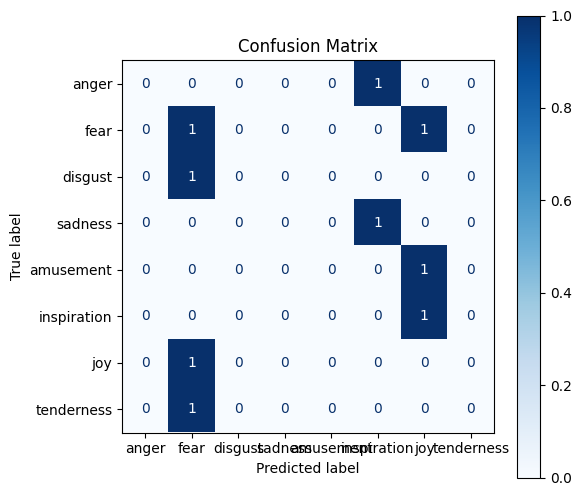

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

def plot_confusion(model, loader, class_names):
    model.eval()
    all_preds = []
    all_labels = []
    with torch.no_grad():
        for X, y in loader:
            X, y = X.to(device), y.to(device)
            out = model(X)
            preds = torch.argmax(out, dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(y.cpu().numpy())
    
    cm = confusion_matrix(all_labels, all_preds, labels=range(len(class_names)))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
    fig, ax = plt.subplots(figsize=(6, 6))
    disp.plot(ax=ax, cmap='Blues', values_format='d')
    plt.title("Confusion Matrix")
    plt.show()

class_names = ['anger', 'fear', 'disgust', 'sadness',
               'amusement', 'inspiration', 'joy', 'tenderness']

plot_confusion(model, test_loader, class_names)


In [30]:
def show_predictions(model, loader):
    model.eval()
    with torch.no_grad():
        for X, y in loader:
            X, y = X.to(device), y.to(device)
            out = model(X)
            preds = torch.argmax(out, dim=1)
            for i in range(len(y)):
                print(f"True: {class_names[y[i]]:12s} | Predicted: {class_names[preds[i]]}")

show_predictions(model, test_loader)


True: fear         | Predicted: joy
True: amusement    | Predicted: joy
True: sadness      | Predicted: inspiration
True: tenderness   | Predicted: fear
True: anger        | Predicted: inspiration
True: joy          | Predicted: fear
True: inspiration  | Predicted: joy
True: disgust      | Predicted: fear
True: fear         | Predicted: fear


# FULL DATASET

In [31]:
import os
import pickle
import hdf5storage
import numpy as np
from tqdm import tqdm

data_dir = r"C:\Users\rajab\Desktop\FACED dataset\Processed_data\Processed_data"
raw_dir = r"C:\Users\rajab\Desktop\FACED dataset\Data\Data"

all_eeg = []
all_labels = []

for i in tqdm(range(123)):
    sub_id = f"sub{str(i).zfill(3)}"
    
    eeg_path = os.path.join(data_dir, f"{sub_id}.pkl")
    mat_path = os.path.join(raw_dir, sub_id, "After_remarks.mat")
    
    if not os.path.exists(eeg_path) or not os.path.exists(mat_path):
        print(f"Missing: {sub_id}")
        continue

    with open(eeg_path, 'rb') as f:
        eeg_data = pickle.load(f)

    try:
        after_remark = hdf5storage.loadmat(mat_path)['After_remark']
        scores_raw = after_remark['score'].squeeze()
        vids_raw = after_remark['vid'].squeeze()
        
        scores = np.array([s.squeeze() for s in scores_raw])    # (28, 12)
        vids = np.array([v.squeeze() for v in vids_raw])        # (28,)
        sorted_idx = np.argsort(vids)
        
        eeg_sorted = eeg_data[sorted_idx]
        labels = np.argmax(scores[sorted_idx, :8], axis=1)      # Top emotion class
    except:
        print(f"Failed to load labels for: {sub_id}")
        continue

    all_eeg.append(eeg_sorted)
    all_labels.append(labels)

all_eeg = np.concatenate(all_eeg, axis=0)      # (3444, 32, 7500)
all_labels = np.concatenate(all_labels, axis=0)  # (3444,)

print("Final EEG shape:", all_eeg.shape)
print("Final labels shape:", all_labels.shape)


100%|██████████| 123/123 [00:09<00:00, 13.22it/s]


Final EEG shape: (3444, 32, 7500)
Final labels shape: (3444,)


In [32]:
# reshape to (N, T, C) → for LSTM
all_eeg_reshaped = all_eeg.transpose(0, 2, 1)  # (3444, 7500, 32)
print("Reshaped EEG:", all_eeg_reshaped.shape)


Reshaped EEG: (3444, 7500, 32)


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from torch.utils.data import Dataset, DataLoader
import torch

class EEGDataset(Dataset):
    def __init__(self, data, labels, scaler=None):
        self.data = data
        N, T, C = data.shape
        flat = data.reshape(-1, C)
        self.scaler = scaler or StandardScaler()
        scaled = self.scaler.fit_transform(flat).reshape(N, T, C)
        self.X = torch.tensor(scaled, dtype=torch.float32)
        self.y = torch.tensor(labels, dtype=torch.long)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

X_train, X_test, y_train, y_test = train_test_split(
    all_eeg_reshaped, all_labels, test_size=0.2, random_state=42, stratify=all_labels
)

train_dataset = EEGDataset(X_train, y_train)
test_dataset = EEGDataset(X_test, y_test, scaler=train_dataset.scaler)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32)


In [34]:
import torch.nn as nn

class VanillaLSTM(nn.Module):
    def __init__(self, input_size=32, hidden_size=64, num_layers=1, num_classes=8):
        super(VanillaLSTM, self).__init__()
        self.lstm = nn.LSTM(input_size=input_size, hidden_size=hidden_size,
                            num_layers=num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_size, num_classes)

    def forward(self, x):
        out, _ = self.lstm(x)
        out = out[:, -1, :]  # use last time step
        out = self.fc(out)
        return out


In [35]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = VanillaLSTM().to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

def train(model, loader, optimizer, criterion):
    model.train()
    total_loss = 0
    for X, y in loader:
        X, y = X.to(device), y.to(device)
        optimizer.zero_grad()
        out = model(X)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    return total_loss / len(loader)

def evaluate(model, loader):
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for X, y in loader:
            X, y = X.to(device), y.to(device)
            out = model(X)
            preds = torch.argmax(out, dim=1)
            correct += (preds == y).sum().item()
            total += y.size(0)
    return correct / total


In [36]:
epochs = 20
for epoch in range(epochs):
    train_loss = train(model, train_loader, optimizer, criterion)
    test_acc = evaluate(model, test_loader)
    print(f"Epoch {epoch+1}/{epochs} - Train Loss: {train_loss:.4f} - Test Acc: {test_acc:.4f}")


Epoch 1/10 - Train Loss: 2.0606 - Test Acc: 0.1727
Epoch 2/10 - Train Loss: 2.0442 - Test Acc: 0.1727
Epoch 3/10 - Train Loss: 2.0423 - Test Acc: 0.1727
Epoch 4/10 - Train Loss: 2.0403 - Test Acc: 0.1655
Epoch 5/10 - Train Loss: 2.0396 - Test Acc: 0.1669
Epoch 6/10 - Train Loss: 2.0377 - Test Acc: 0.1669
Epoch 7/10 - Train Loss: 2.0420 - Test Acc: 0.1727
Epoch 8/10 - Train Loss: 2.0359 - Test Acc: 0.1713
Epoch 9/10 - Train Loss: 2.0384 - Test Acc: 0.1771
Epoch 10/10 - Train Loss: 2.0364 - Test Acc: 0.1742


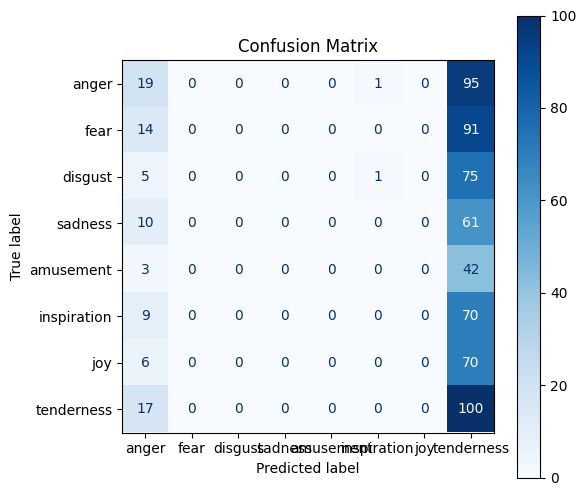

In [ ]:
plot_confusion(model, test_loader, class_names)


In [ ]:
show_predictions(model, test_loader)


True: anger        | Predicted: tenderness
True: joy          | Predicted: tenderness
True: joy          | Predicted: tenderness
True: disgust      | Predicted: tenderness
True: inspiration  | Predicted: anger
True: disgust      | Predicted: tenderness
True: tenderness   | Predicted: tenderness
True: disgust      | Predicted: tenderness
True: anger        | Predicted: tenderness
True: joy          | Predicted: tenderness
True: anger        | Predicted: tenderness
True: amusement    | Predicted: tenderness
True: anger        | Predicted: tenderness
True: tenderness   | Predicted: anger
True: inspiration  | Predicted: tenderness
True: joy          | Predicted: tenderness
True: fear         | Predicted: tenderness
True: tenderness   | Predicted: tenderness
True: joy          | Predicted: tenderness
True: anger        | Predicted: tenderness
True: disgust      | Predicted: tenderness
True: disgust      | Predicted: tenderness
True: tenderness   | Predicted: tenderness
True: tenderness   | 

# CNN + LSTM

In [40]:
class CNNLSTM(nn.Module):
    def __init__(self, input_size=32, num_classes=8, cnn_out_channels=64, lstm_hidden=128):
        super(CNNLSTM, self).__init__()
        
        # 1D CNN: input (B, C_in, T)
        self.conv1 = nn.Conv1d(in_channels=input_size, out_channels=cnn_out_channels, kernel_size=7, padding=3)
        self.bn1 = nn.BatchNorm1d(cnn_out_channels)
        self.relu = nn.ReLU()
        self.pool = nn.MaxPool1d(kernel_size=4)  # Reduce time resolution
        
        # LSTM input will be (B, new_seq_len, cnn_out_channels)
        self.lstm = nn.LSTM(input_size=cnn_out_channels, hidden_size=lstm_hidden,
                            batch_first=True, num_layers=1)
        
        self.fc = nn.Linear(lstm_hidden, num_classes)

    def forward(self, x):
        # x: (B, T, C) → (B, C, T)
        x = x.permute(0, 2, 1)
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu(x)
        x = self.pool(x)   # (B, C_out, T//4)

        # (B, C_out, T') → (B, T', C_out) for LSTM
        x = x.permute(0, 2, 1)
        out, _ = self.lstm(x)
        out = out[:, -1, :]  # last hidden state
        out = self.fc(out)
        return out


In [41]:
model = CNNLSTM().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)


In [42]:
for epoch in range(10):
    train_loss = train(model, train_loader, optimizer, criterion)
    test_acc = evaluate(model, test_loader)
    print(f"Epoch {epoch+1}/10 - Train Loss: {train_loss:.4f} - Test Acc: {test_acc:.4f}")


Epoch 1/10 - Train Loss: 2.0605 - Test Acc: 0.1713
Epoch 2/10 - Train Loss: 2.0425 - Test Acc: 0.1669
Epoch 3/10 - Train Loss: 2.0331 - Test Acc: 0.1727
Epoch 4/10 - Train Loss: 2.0324 - Test Acc: 0.1727
Epoch 5/10 - Train Loss: 2.0260 - Test Acc: 0.1713
Epoch 6/10 - Train Loss: 2.0162 - Test Acc: 0.1684
Epoch 7/10 - Train Loss: 2.0124 - Test Acc: 0.1756
Epoch 8/10 - Train Loss: 2.0021 - Test Acc: 0.1727
Epoch 9/10 - Train Loss: 1.9875 - Test Acc: 0.1742
Epoch 10/10 - Train Loss: 1.9929 - Test Acc: 0.1655


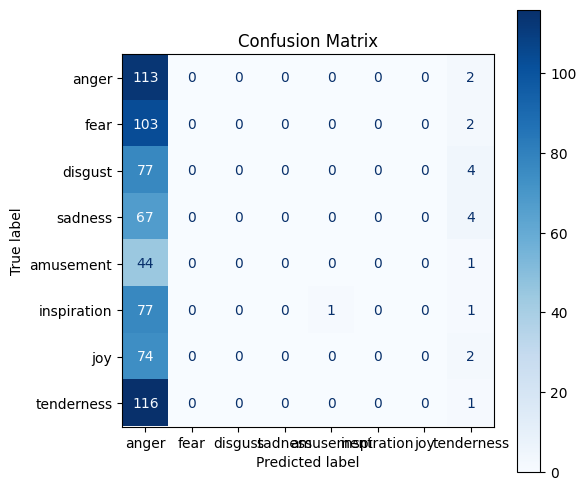

In [ ]:
plot_confusion(model, test_loader, class_names)


In [ ]:
show_predictions(model, test_loader)


True: anger        | Predicted: anger
True: joy          | Predicted: anger
True: joy          | Predicted: anger
True: disgust      | Predicted: anger
True: inspiration  | Predicted: anger
True: disgust      | Predicted: anger
True: tenderness   | Predicted: anger
True: disgust      | Predicted: anger
True: anger        | Predicted: anger
True: joy          | Predicted: anger
True: anger        | Predicted: anger
True: amusement    | Predicted: anger
True: anger        | Predicted: anger
True: tenderness   | Predicted: tenderness
True: inspiration  | Predicted: anger
True: joy          | Predicted: anger
True: fear         | Predicted: anger
True: tenderness   | Predicted: anger
True: joy          | Predicted: anger
True: anger        | Predicted: anger
True: disgust      | Predicted: anger
True: disgust      | Predicted: anger
True: tenderness   | Predicted: anger
True: tenderness   | Predicted: anger
True: fear         | Predicted: anger
True: anger        | Predicted: anger
True: s

# BiLSTM

In [45]:
class BiLSTMClassifier(nn.Module):
    def __init__(self, input_size=32, hidden_size=64, num_layers=1, num_classes=8):
        super(BiLSTMClassifier, self).__init__()
        self.bilstm = nn.LSTM(input_size=input_size,
                              hidden_size=hidden_size,
                              num_layers=num_layers,
                              bidirectional=True,
                              batch_first=True)
        self.fc = nn.Linear(hidden_size * 2, num_classes)

    def forward(self, x):
        out, _ = self.bilstm(x)  # out: (B, T, H*2)
        out = out[:, -1, :]      # get last time step
        out = self.fc(out)       # (B, num_classes)
        return out


In [46]:
model = BiLSTMClassifier().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)


In [47]:
for epoch in range(10):
    train_loss = train(model, train_loader, optimizer, criterion)
    test_acc = evaluate(model, test_loader)
    print(f"Epoch {epoch+1}/10 - Train Loss: {train_loss:.4f} - Test Acc: {test_acc:.4f}")


Epoch 1/10 - Train Loss: 2.0545 - Test Acc: 0.1727
Epoch 2/10 - Train Loss: 2.0439 - Test Acc: 0.1684
Epoch 3/10 - Train Loss: 2.0412 - Test Acc: 0.1785
Epoch 4/10 - Train Loss: 2.0411 - Test Acc: 0.1742
Epoch 5/10 - Train Loss: 2.0386 - Test Acc: 0.1669
Epoch 6/10 - Train Loss: 2.0424 - Test Acc: 0.1698
Epoch 7/10 - Train Loss: 2.0406 - Test Acc: 0.1727
Epoch 8/10 - Train Loss: 2.0358 - Test Acc: 0.1742
Epoch 9/10 - Train Loss: 2.0341 - Test Acc: 0.1742
Epoch 10/10 - Train Loss: 2.0344 - Test Acc: 0.1684


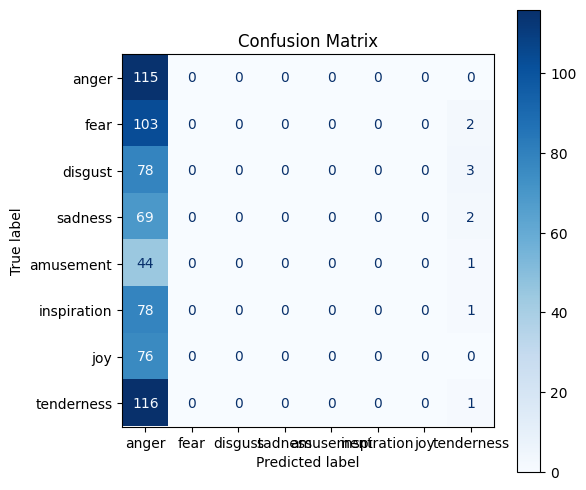

In [ ]:
plot_confusion(model, test_loader, class_names)


In [ ]:
show_predictions(model, test_loader)


True: anger        | Predicted: anger
True: joy          | Predicted: anger
True: joy          | Predicted: anger
True: disgust      | Predicted: tenderness
True: inspiration  | Predicted: anger
True: disgust      | Predicted: anger
True: tenderness   | Predicted: anger
True: disgust      | Predicted: anger
True: anger        | Predicted: anger
True: joy          | Predicted: anger
True: anger        | Predicted: anger
True: amusement    | Predicted: anger
True: anger        | Predicted: anger
True: tenderness   | Predicted: tenderness
True: inspiration  | Predicted: anger
True: joy          | Predicted: anger
True: fear         | Predicted: anger
True: tenderness   | Predicted: anger
True: joy          | Predicted: anger
True: anger        | Predicted: anger
True: disgust      | Predicted: anger
True: disgust      | Predicted: anger
True: tenderness   | Predicted: anger
True: tenderness   | Predicted: anger
True: fear         | Predicted: anger
True: anger        | Predicted: anger
Tr

# Attention + LSTM

In [50]:
class LSTMAttention(nn.Module):
    def __init__(self, input_size=32, hidden_size=64, num_classes=8):
        super(LSTMAttention, self).__init__()
        self.lstm = nn.LSTM(input_size=input_size, hidden_size=hidden_size,
                            batch_first=True, bidirectional=False)
        self.attn = nn.Linear(hidden_size, 1)
        self.fc = nn.Linear(hidden_size, num_classes)

    def forward(self, x):
        # x: (B, T, C)
        out, _ = self.lstm(x)        # out: (B, T, H)
        
        attn_weights = self.attn(out)  # (B, T, 1)
        attn_weights = torch.softmax(attn_weights, dim=1)  # normalize over time

        context = torch.sum(attn_weights * out, dim=1)     # weighted sum (B, H)

        out = self.fc(context)  # (B, num_classes)
        return out, attn_weights.squeeze(-1)  # return weights too for visualization


In [51]:
model = LSTMAttention().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)


In [52]:
def train(model, loader, optimizer, criterion):
    model.train()
    total_loss = 0
    for X, y in loader:
        X, y = X.to(device), y.to(device)
        optimizer.zero_grad()
        out = model(X)[0]
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    return total_loss / len(loader)

def evaluate(model, loader):
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for X, y in loader:
            X, y = X.to(device), y.to(device)
            out = model(X)[0]
            preds = torch.argmax(out, dim=1)
            correct += (preds == y).sum().item()
            total += y.size(0)
    return correct / total


In [53]:
epochs = 10
for epoch in range(epochs):
    train_loss = train(model, train_loader, optimizer, criterion)
    test_acc = evaluate(model, test_loader)
    print(f"Epoch {epoch+1}/{epochs} - Train Loss: {train_loss:.4f} - Test Acc: {test_acc:.4f}")


Epoch 1/10 - Train Loss: 2.0610 - Test Acc: 0.1727
Epoch 2/10 - Train Loss: 2.0470 - Test Acc: 0.1713
Epoch 3/10 - Train Loss: 2.0426 - Test Acc: 0.1713
Epoch 4/10 - Train Loss: 2.0438 - Test Acc: 0.1713
Epoch 5/10 - Train Loss: 2.0392 - Test Acc: 0.1713
Epoch 6/10 - Train Loss: 2.0416 - Test Acc: 0.1713
Epoch 7/10 - Train Loss: 2.0397 - Test Acc: 0.1713
Epoch 8/10 - Train Loss: 2.0391 - Test Acc: 0.1669
Epoch 9/10 - Train Loss: 2.0385 - Test Acc: 0.1713
Epoch 10/10 - Train Loss: 2.0369 - Test Acc: 0.1713


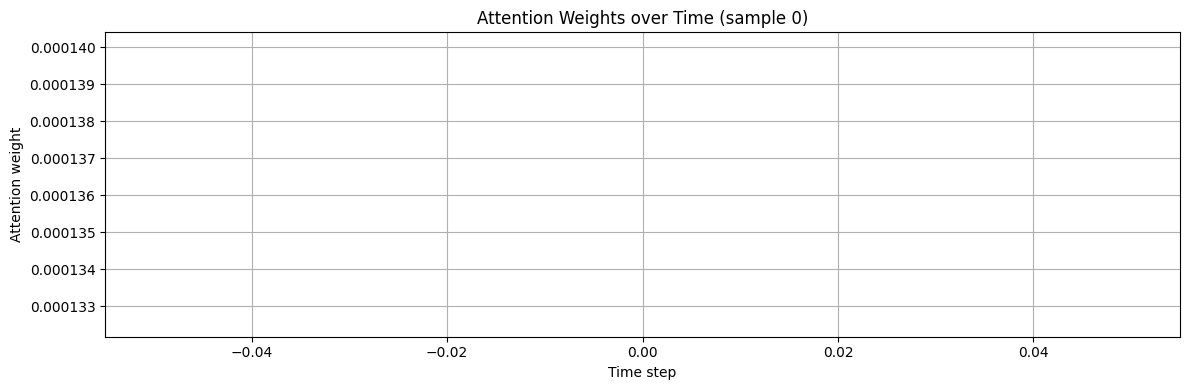

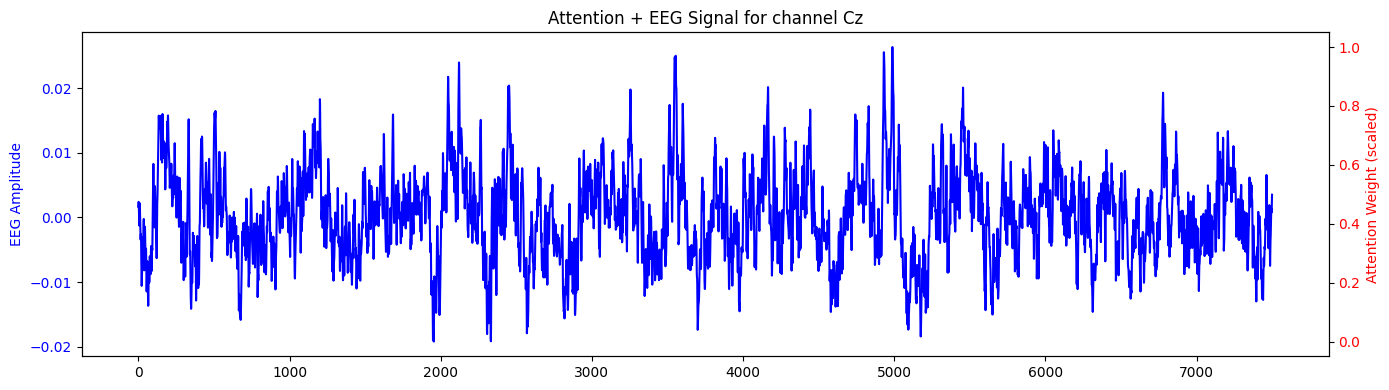

In [55]:
channel_name = 'Cz'
channel_names = [
    "Fp1","Fp2","Fz","F3","A2","CP1","CP2","CP5",
    "C4","C3","T4","T3","O1","Oz","FC1","FC2",
    "PO3","PO4","T5","T6","Cz","P4","FC5","FC6",
    "O2","F8","F7","F4","A1","P3","Pz","CP6"
]
channel_idx = channel_names.index(channel_name)

X_sample, y_sample = test_dataset[0]
signal = X_sample[:, channel_idx].numpy()  # (T,)
X_sample = X_sample.unsqueeze(0).to(device)

model.eval()
with torch.no_grad():
    _, attn_weights = model(X_sample)
attn_weights = attn_weights.cpu().numpy()

# normalize attention to [0, 1] for plotting
attn_norm = (attn_weights - attn_weights.min()) / (attn_weights.max() - attn_weights.min())

fig, ax1 = plt.subplots(figsize=(14, 4))

# EEG signal
ax1.plot(signal, color='blue', label=f'EEG signal ({channel_name})')
ax1.set_ylabel('EEG Amplitude', color='blue')
ax1.tick_params(axis='y', labelcolor='blue')

# Attention (scaled)
ax2 = ax1.twinx()
ax2.plot(attn_norm, color='red', alpha=0.6, label='Attention weight')
ax2.set_ylabel('Attention Weight (scaled)', color='red')
ax2.tick_params(axis='y', labelcolor='red')

plt.title(f"Attention + EEG Signal for channel {channel_name}")
fig.tight_layout()
plt.show()


# Multi-branch CNN

In [57]:
class MultiBranchCNN(nn.Module):
    def __init__(self, num_channels=32, seq_len=7500, conv_out=16, num_classes=8):
        super(MultiBranchCNN, self).__init__()
        self.branches = nn.ModuleList([
            nn.Sequential(
                nn.Conv1d(1, conv_out, kernel_size=7, padding=3),
                nn.BatchNorm1d(conv_out),
                nn.ReLU(),
                nn.AdaptiveAvgPool1d(1)  # compress time
            )
            for _ in range(num_channels)
        ])
        self.classifier = nn.Linear(num_channels * conv_out, num_classes)

    def forward(self, x):
        # x: (B, T, C) → split C into branches
        branch_outputs = []
        for i, branch in enumerate(self.branches):
            # x[:, :, i]: (B, T), → add channel dim: (B, 1, T)
            xi = x[:, :, i].unsqueeze(1)
            yi = branch(xi)  # (B, conv_out, 1)
            yi = yi.squeeze(-1)  # (B, conv_out)
            branch_outputs.append(yi)
        
        # concat all branches → (B, conv_out * channels)
        features = torch.cat(branch_outputs, dim=1)
        out = self.classifier(features)  # (B, num_classes)
        return out


In [58]:
model = MultiBranchCNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)


In [60]:
def train(model, loader, optimizer, criterion):
    model.train()
    total_loss = 0
    for X, y in loader:
        X, y = X.to(device), y.to(device)
        optimizer.zero_grad()
        out = model(X)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    return total_loss / len(loader)

def evaluate(model, loader):
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for X, y in loader:
            X, y = X.to(device), y.to(device)
            out = model(X)
            preds = torch.argmax(out, dim=1)
            correct += (preds == y).sum().item()
            total += y.size(0)
    return correct / total


In [61]:
for epoch in range(10):
    train_loss = train(model, train_loader, optimizer, criterion)
    test_acc = evaluate(model, test_loader)
    print(f"Epoch {epoch+1}/10 - Train Loss: {train_loss:.4f} - Test Acc: {test_acc:.4f}")


Epoch 1/10 - Train Loss: 2.0855 - Test Acc: 0.1727
Epoch 2/10 - Train Loss: 2.0732 - Test Acc: 0.1727
Epoch 3/10 - Train Loss: 2.0776 - Test Acc: 0.1669
Epoch 4/10 - Train Loss: 2.0615 - Test Acc: 0.1669
Epoch 5/10 - Train Loss: 2.0653 - Test Acc: 0.1713
Epoch 6/10 - Train Loss: 2.0501 - Test Acc: 0.1698
Epoch 7/10 - Train Loss: 2.0524 - Test Acc: 0.1698
Epoch 8/10 - Train Loss: 2.0493 - Test Acc: 0.1669
Epoch 9/10 - Train Loss: 2.0457 - Test Acc: 0.1713
Epoch 10/10 - Train Loss: 2.0542 - Test Acc: 0.1684


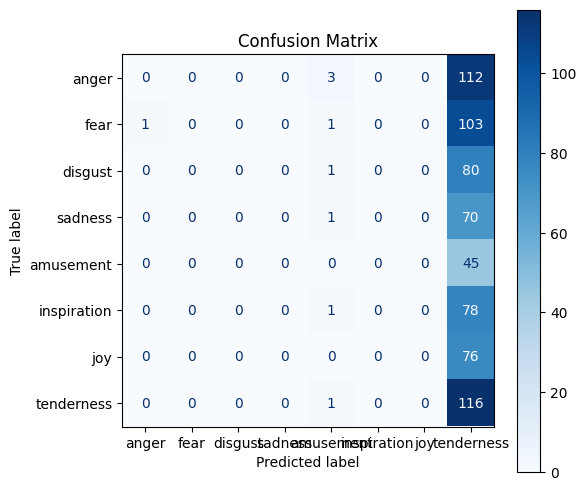

In [ ]:
plot_confusion(model, test_loader, class_names)


In [ ]:
show_predictions(model, test_loader)


True: anger        | Predicted: tenderness
True: joy          | Predicted: tenderness
True: joy          | Predicted: tenderness
True: disgust      | Predicted: tenderness
True: inspiration  | Predicted: tenderness
True: disgust      | Predicted: tenderness
True: tenderness   | Predicted: tenderness
True: disgust      | Predicted: tenderness
True: anger        | Predicted: tenderness
True: joy          | Predicted: tenderness
True: anger        | Predicted: tenderness
True: amusement    | Predicted: tenderness
True: anger        | Predicted: tenderness
True: tenderness   | Predicted: tenderness
True: inspiration  | Predicted: tenderness
True: joy          | Predicted: tenderness
True: fear         | Predicted: tenderness
True: tenderness   | Predicted: tenderness
True: joy          | Predicted: tenderness
True: anger        | Predicted: tenderness
True: disgust      | Predicted: tenderness
True: disgust      | Predicted: tenderness
True: tenderness   | Predicted: tenderness
True: tende

# Simple EEGNet

In [ ]:
class EEGNet(nn.Module):
    def __init__(self, num_classes=8, channels=32, samples=7500, dropout_rate=0.5):
        super(EEGNet, self).__init__()
        self.firstconv = nn.Sequential(
            nn.Conv2d(1, 8, (1, 64), padding=(0, 32), bias=False),  # temporal conv
            nn.BatchNorm2d(8)
        )
        self.depthwiseConv = nn.Sequential(
            nn.Conv2d(8, 16, (channels, 1), groups=8, bias=False),
            nn.BatchNorm2d(16),
            nn.ELU(),
            nn.AvgPool2d((1, 4)),
            nn.Dropout(dropout_rate)
        )
        self.separableConv = nn.Sequential(
            nn.Conv2d(16, 16, (1, 16), padding=(0, 8), bias=False),
            nn.BatchNorm2d(16),
            nn.ELU(),
            nn.AvgPool2d((1, 8)),
            nn.Dropout(dropout_rate)
        )
        final_len = samples // (4 * 8) 
        self.classify = nn.Linear(16 * final_len, num_classes)

    def forward(self, x):
        # x: (B, T, C) → (B, 1, C, T)
        x = x.permute(0, 2, 1).unsqueeze(1)
        x = self.firstconv(x)
        x = self.depthwiseConv(x)
        x = self.separableConv(x)
        x = x.reshape(x.size(0), -1)
        return self.classify(x)


In [65]:
model = EEGNet().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)


In [66]:
for epoch in range(10):
    train_loss = train(model, train_loader, optimizer, criterion)
    test_acc = evaluate(model, test_loader)
    print(f"Epoch {epoch+1}/10 - Train Loss: {train_loss:.4f} - Test Acc: {test_acc:.4f}")


Epoch 1/10 - Train Loss: 2.1453 - Test Acc: 0.1669
Epoch 2/10 - Train Loss: 2.0592 - Test Acc: 0.1567
Epoch 3/10 - Train Loss: 2.0141 - Test Acc: 0.1480
Epoch 4/10 - Train Loss: 1.9252 - Test Acc: 0.1509
Epoch 5/10 - Train Loss: 1.8553 - Test Acc: 0.1655
Epoch 6/10 - Train Loss: 1.7639 - Test Acc: 0.1451
Epoch 7/10 - Train Loss: 1.6947 - Test Acc: 0.1640
Epoch 8/10 - Train Loss: 1.6432 - Test Acc: 0.1640
Epoch 9/10 - Train Loss: 1.5848 - Test Acc: 0.1640
Epoch 10/10 - Train Loss: 1.5749 - Test Acc: 0.1611


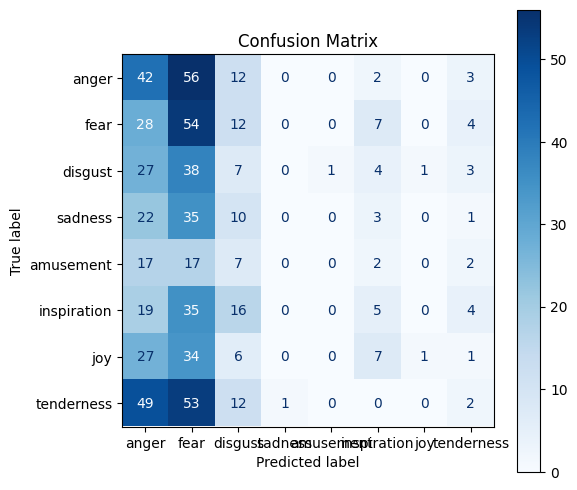

In [ ]:
plot_confusion(model, test_loader, class_names)


In [ ]:
show_predictions(model, test_loader)


True: anger        | Predicted: fear
True: joy          | Predicted: anger
True: joy          | Predicted: fear
True: disgust      | Predicted: anger
True: inspiration  | Predicted: disgust
True: disgust      | Predicted: fear
True: tenderness   | Predicted: fear
True: disgust      | Predicted: anger
True: anger        | Predicted: anger
True: joy          | Predicted: fear
True: anger        | Predicted: anger
True: amusement    | Predicted: tenderness
True: anger        | Predicted: fear
True: tenderness   | Predicted: fear
True: inspiration  | Predicted: tenderness
True: joy          | Predicted: anger
True: fear         | Predicted: fear
True: tenderness   | Predicted: fear
True: joy          | Predicted: inspiration
True: anger        | Predicted: fear
True: disgust      | Predicted: fear
True: disgust      | Predicted: fear
True: tenderness   | Predicted: fear
True: tenderness   | Predicted: fear
True: fear         | Predicted: anger
True: anger        | Predicted: fear
True: sad

# Advanced EEGNet

In [69]:
class EEGNet_Advanced(nn.Module):
    def __init__(self, num_classes=8, channels=32, samples=7500, 
                 dropout_rate=0.5, F1=8, D=2, kernel_length=128):
        super(EEGNet_Advanced, self).__init__()
        
        self.firstconv = nn.Sequential(
            nn.Conv2d(1, F1, (1, kernel_length), padding=(0, kernel_length // 2), bias=False),
            nn.BatchNorm2d(F1)
        )
        
        self.depthwise = nn.Sequential(
            nn.Conv2d(F1, F1 * D, (channels, 1), groups=F1, bias=False),
            nn.BatchNorm2d(F1 * D),
            nn.ELU(),
            nn.AvgPool2d((1, 4)),
            nn.Dropout(dropout_rate)
        )
        
        self.separable = nn.Sequential(
            nn.Conv2d(F1 * D, F1 * D, (1, 16), padding=(0, 8), bias=False),
            nn.BatchNorm2d(F1 * D),
            nn.ELU(),
            nn.AvgPool2d((1, 8)),
            nn.Dropout(dropout_rate)
        )
        
        final_len = samples // (4 * 8)
        self.classifier = nn.Linear(F1 * D * final_len, num_classes)

    def forward(self, x):
        # x: (B, T, C) → (B, 1, C, T)
        x = x.permute(0, 2, 1).unsqueeze(1)
        x = self.firstconv(x)
        x = self.depthwise(x)
        x = self.separable(x)
        x = x.view(x.size(0), -1)
        return self.classifier(x)


In [70]:
model = EEGNet_Advanced().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)


In [71]:
for epoch in range(10):
    train_loss = train(model, train_loader, optimizer, criterion)
    test_acc = evaluate(model, test_loader)
    print(f"Epoch {epoch+1}/10 - Train Loss: {train_loss:.4f} - Test Acc: {test_acc:.4f}")


Epoch 1/10 - Train Loss: 2.1575 - Test Acc: 0.1684
Epoch 2/10 - Train Loss: 2.0362 - Test Acc: 0.1698
Epoch 3/10 - Train Loss: 1.9852 - Test Acc: 0.1219
Epoch 4/10 - Train Loss: 1.9157 - Test Acc: 0.1669
Epoch 5/10 - Train Loss: 1.8640 - Test Acc: 0.1771
Epoch 6/10 - Train Loss: 1.7675 - Test Acc: 0.1698
Epoch 7/10 - Train Loss: 1.7445 - Test Acc: 0.1771
Epoch 8/10 - Train Loss: 1.6710 - Test Acc: 0.1597
Epoch 9/10 - Train Loss: 1.6520 - Test Acc: 0.1901
Epoch 10/10 - Train Loss: 1.6048 - Test Acc: 0.1829


In [ ]:
plot_confusion(model, test_loader, class_names)

In [ ]:
show_predictions(model, test_loader)

# DeepConvNet

In [75]:
class DeepConvNet(nn.Module):
    def __init__(self, num_classes=8, channels=32, samples=7500):
        super(DeepConvNet, self).__init__()
        self.model = nn.Sequential(
            nn.Conv2d(1, 25, (1, 10), padding=(0, 5)),        # Temporal Conv
            nn.Conv2d(25, 25, (channels, 1)),                 # Spatial Conv
            nn.BatchNorm2d(25),
            nn.ELU(),
            nn.MaxPool2d((1, 3)),
            nn.Dropout(0.5),

            nn.Conv2d(25, 50, (1, 10), padding=(0, 5)),
            nn.BatchNorm2d(50),
            nn.ELU(),
            nn.MaxPool2d((1, 3)),
            nn.Dropout(0.5),

            nn.Conv2d(50, 100, (1, 10), padding=(0, 5)),
            nn.BatchNorm2d(100),
            nn.ELU(),
            nn.MaxPool2d((1, 3)),
            nn.Dropout(0.5),

            nn.Conv2d(100, 200, (1, 10), padding=(0, 5)),
            nn.BatchNorm2d(200),
            nn.ELU(),
            nn.MaxPool2d((1, 3)),
            nn.Dropout(0.5),
        )

        with torch.no_grad():
            dummy_input = torch.zeros(1, 1, channels, samples)
            dummy_out = self.model(dummy_input)
            flattened_dim = dummy_out.view(1, -1).shape[1]

        self.classifier = nn.Linear(flattened_dim, num_classes)


    def forward(self, x):
        # x: (B, T, C) → (B, 1, C, T)
        x = x.permute(0, 2, 1).unsqueeze(1)
        x = self.model(x)
        x = x.view(x.size(0), -1)
        return self.classifier(x)


In [76]:
model = DeepConvNet().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)


In [ ]:
for epoch in range(10):
    train_loss = train(model, train_loader, optimizer, criterion)
    test_acc = evaluate(model, test_loader)
    print(f"Epoch {epoch+1}/10 - Train Loss: {train_loss:.4f} - Test Acc: {test_acc:.4f}")


In [ ]:
plot_confusion(model, test_loader, class_names)

In [ ]:
show_predictions(model, test_loader)

# 1D-CNN + Residual Blocks

In [78]:
class ResidualBlock1D(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size=7, stride=1):
        super(ResidualBlock1D, self).__init__()
        padding = kernel_size // 2
        self.conv1 = nn.Conv1d(in_channels, out_channels, kernel_size, padding=padding, stride=stride)
        self.bn1 = nn.BatchNorm1d(out_channels)
        self.relu = nn.ReLU()
        self.conv2 = nn.Conv1d(out_channels, out_channels, kernel_size, padding=padding)
        self.bn2 = nn.BatchNorm1d(out_channels)

        self.downsample = nn.Sequential()
        if in_channels != out_channels or stride != 1:
            self.downsample = nn.Sequential(
                nn.Conv1d(in_channels, out_channels, kernel_size=1, stride=stride),
                nn.BatchNorm1d(out_channels)
            )

    def forward(self, x):
        identity = self.downsample(x)
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out += identity
        return self.relu(out)


In [79]:
class Residual1DCNN(nn.Module):
    def __init__(self, num_classes=8, input_channels=32, input_length=7500):
        super(Residual1DCNN, self).__init__()
        self.initial = nn.Sequential(
            nn.Conv1d(input_channels, 64, kernel_size=7, padding=3),
            nn.BatchNorm1d(64),
            nn.ReLU()
        )
        self.block1 = ResidualBlock1D(64, 64)
        self.block2 = ResidualBlock1D(64, 128, stride=2)
        self.block3 = ResidualBlock1D(128, 256, stride=2)

        self.pool = nn.AdaptiveAvgPool1d(1)
        self.fc = nn.Linear(256, num_classes)

    def forward(self, x):
        x = x.permute(0, 2, 1)  # (B, T, C) → (B, C, T)
        x = self.initial(x)
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.pool(x).squeeze(-1)
        return self.fc(x)


In [80]:
model = Residual1DCNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)


In [81]:
for epoch in range(10):
    train_loss = train(model, train_loader, optimizer, criterion)
    test_acc = evaluate(model, test_loader)
    print(f"Epoch {epoch+1}/10 - Train Loss: {train_loss:.4f} - Test Acc: {test_acc:.4f}")


Epoch 1/10 - Train Loss: 2.0818 - Test Acc: 0.1524
Epoch 2/10 - Train Loss: 2.0676 - Test Acc: 0.1713
Epoch 3/10 - Train Loss: 2.0535 - Test Acc: 0.1698
Epoch 4/10 - Train Loss: 2.0515 - Test Acc: 0.1524
Epoch 5/10 - Train Loss: 2.0531 - Test Acc: 0.1713
Epoch 6/10 - Train Loss: 2.0496 - Test Acc: 0.1669
Epoch 7/10 - Train Loss: 2.0460 - Test Acc: 0.1684
Epoch 8/10 - Train Loss: 2.0439 - Test Acc: 0.1713
Epoch 9/10 - Train Loss: 2.0474 - Test Acc: 0.1713
Epoch 10/10 - Train Loss: 2.0459 - Test Acc: 0.1538


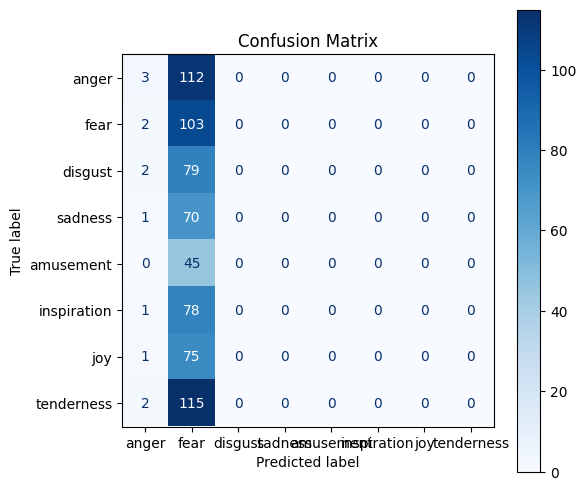

In [82]:
plot_confusion(model, test_loader, class_names)

In [83]:
show_predictions(model, test_loader)

True: anger        | Predicted: fear
True: joy          | Predicted: fear
True: joy          | Predicted: fear
True: disgust      | Predicted: fear
True: inspiration  | Predicted: fear
True: disgust      | Predicted: fear
True: tenderness   | Predicted: fear
True: disgust      | Predicted: fear
True: anger        | Predicted: fear
True: joy          | Predicted: fear
True: anger        | Predicted: fear
True: amusement    | Predicted: fear
True: anger        | Predicted: fear
True: tenderness   | Predicted: anger
True: inspiration  | Predicted: fear
True: joy          | Predicted: fear
True: fear         | Predicted: fear
True: tenderness   | Predicted: fear
True: joy          | Predicted: fear
True: anger        | Predicted: fear
True: disgust      | Predicted: fear
True: disgust      | Predicted: fear
True: tenderness   | Predicted: fear
True: tenderness   | Predicted: fear
True: fear         | Predicted: fear
True: anger        | Predicted: fear
True: sadness      | Predicted: fear


# Graph Neural Network

In [84]:
import mne
montage = mne.channels.make_standard_montage('standard_1020')

channel_names = [
    "Fp1","Fp2","Fz","F3","F4","F7","F8","FC1","FC2","FC5","FC6",
    "C3","C4","Cz","CP1","CP2","CP5","CP6","P3","P4","Pz",
    "O1","O2","Oz","PO3","PO4","T3","T4","T5","T6","A1","A2"
]
positions = []
for ch in channel_names:
    if ch in montage.get_positions()['ch_pos']:
        pos = montage.get_positions()['ch_pos'][ch]
        positions.append(pos)
    else:
        print("Missing:", ch)

positions = np.array(positions)
print("Loaded positions shape:", positions.shape)


Loaded positions shape: (32, 3)


Adjacency matrix shape: (32, 32)


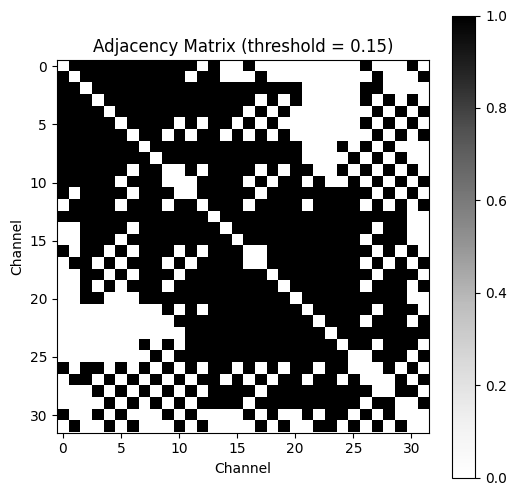

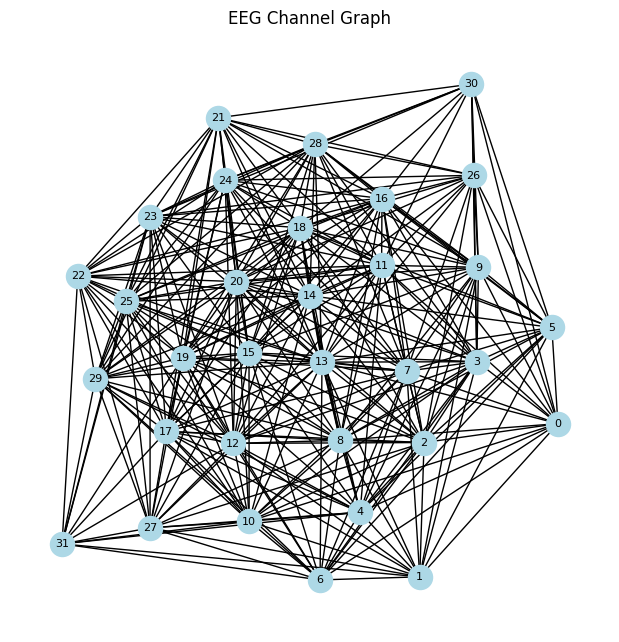

In [85]:
from scipy.spatial.distance import cdist
import networkx as nx
import matplotlib.pyplot as plt

dist_matrix = cdist(positions, positions, metric='euclidean')

threshold = 0.15
adj_matrix = (dist_matrix < threshold).astype(int)
np.fill_diagonal(adj_matrix, 0)

print("Adjacency matrix shape:", adj_matrix.shape)

plt.figure(figsize=(6, 6))
plt.imshow(adj_matrix, cmap='Greys')
plt.title("Adjacency Matrix (threshold = 0.15)")
plt.xlabel("Channel")
plt.ylabel("Channel")
plt.colorbar()
plt.show()

G = nx.from_numpy_array(adj_matrix)
plt.figure(figsize=(6, 6))
nx.draw(G, with_labels=True, node_color='lightblue', font_size=8)
plt.title("EEG Channel Graph")
plt.show()


In [ ]:
from torch_geometric.data import Data
import torch

def eeg_to_graph(eeg_sample, label, adj_matrix):
    node_features = torch.tensor(eeg_sample.mean(axis=1)).unsqueeze(1).float()  # shape (32, 1)
    edge_index = torch.tensor(np.array(adj_matrix).nonzero(), dtype=torch.long)
    data = Data(x=node_features, edge_index=edge_index, y=torch.tensor([label], dtype=torch.long))
    return data


In [ ]:
import pickle
from torch_geometric.data import Data
import os
from scipy.io import loadmat

def load_labels_fixed(mat_path):
    mat = loadmat(mat_path)
    after_remark = mat['After_remark']

    # Extract and flatten
    raw_scores = after_remark['score'].squeeze()
    raw_vids = after_remark['vid'].squeeze()

    scores = np.array([s.squeeze() for s in raw_scores])        # shape: (28, 12)
    vids = np.array([v.squeeze() for v in raw_vids])            # shape: (28,)

    # Sort by video ID
    sorted_idx = np.argsort(vids)
    labels = np.argmax(scores[sorted_idx, :8], axis=1)          # only top-8 emotion scores

    return labels, sorted_idx

def convert_all_to_graphs(processed_dir, label_dir, adj_matrix):
    all_graphs = []
    folders = sorted(os.listdir(processed_dir))
    
    for folder in folders:
        sub_path = os.path.join(processed_dir, folder)
        if not sub_path.endswith('.pkl'):
            continue

        # load EEG data
        with open(sub_path, 'rb') as f:
            eeg_data = pickle.load(f)  # shape: (28, 32, 7500)

        # load labels
        sub_id = folder.split('.')[0]  # sub000
        label_path = os.path.join(label_dir, sub_id, 'After_remarks.mat')
        labels, sorted_idx = load_labels_fixed(label_path)

        eeg_data = eeg_data[sorted_idx]

        for i in range(len(eeg_data)):
            eeg_trial = eeg_data[i]  # (32, 7500)
            label = labels[i]

            node_features = torch.tensor(eeg_trial.mean(axis=1)).unsqueeze(1).float()
            edge_index = torch.tensor(np.array(adj_matrix).nonzero(), dtype=torch.long)
            data = Data(x=node_features, edge_index=edge_index, y=torch.tensor(label))
            all_graphs.append(data)
    
    print(f"Total graphs created: {len(all_graphs)}")
    return all_graphs

processed_dir = r"C:\Users\rajab\Desktop\FACED dataset\Processed_data\Processed_data"
label_dir = r"C:\Users\rajab\Desktop\FACED dataset\Data\Data"

all_graphs = convert_all_to_graphs(processed_dir, label_dir, adj_matrix)


Total graphs created: 3444


In [96]:
from torch_geometric.nn import GCNConv
import torch.nn.functional as F
from torch_geometric.nn import global_mean_pool


class GCN_EEG(nn.Module):
    def __init__(self, in_channels=1, hidden_channels=16, num_classes=8):
        super(GCN_EEG, self).__init__()
        self.conv1 = GCNConv(in_channels, hidden_channels)
        self.conv2 = GCNConv(hidden_channels, hidden_channels)
        self.fc = nn.Linear(hidden_channels, num_classes)

    def forward(self, data):
        x, edge_index, batch = data.x, data.edge_index, data.batch
        x = self.conv1(x, edge_index)
        x = F.relu(x)
        x = self.conv2(x, edge_index)
        x = F.relu(x)
        x = global_mean_pool(x, batch)  # ← pooling per graph
        return self.fc(x)



In [ ]:
from torch_geometric.loader import DataLoader

from sklearn.model_selection import train_test_split
train_graphs, test_graphs = train_test_split(all_graphs, test_size=0.2, random_state=42, stratify=[g.y.item() for g in all_graphs])

train_loader = DataLoader(train_graphs, batch_size=32, shuffle=True)
test_loader = DataLoader(test_graphs, batch_size=32)

model = GCN_EEG().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()


In [98]:
def train(model, loader):
    model.train()
    total_loss = 0
    for data in loader:
        data = data.to(device)
        optimizer.zero_grad()
        out = model(data)
        loss = criterion(out, data.y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    return total_loss / len(loader)

def test(model, loader):
    model.eval()
    correct = 0
    total = 0
    for data in loader:
        data = data.to(device)
        out = model(data)
        pred = out.argmax(dim=1)
        correct += (pred == data.y).sum().item()
        total += data.y.size(0)
    return correct / total

In [99]:
for epoch in range(1, 11):
    loss = train(model, train_loader)
    acc = test(model, test_loader)
    print(f"Epoch {epoch}/10 - Loss: {loss:.4f} - Test Acc: {acc:.4f}")

Epoch 1/10 - Loss: 2.1059 - Test Acc: 0.1176
Epoch 2/10 - Loss: 2.0739 - Test Acc: 0.1669
Epoch 3/10 - Loss: 2.0553 - Test Acc: 0.1669
Epoch 4/10 - Loss: 2.0484 - Test Acc: 0.1669
Epoch 5/10 - Loss: 2.0469 - Test Acc: 0.1669
Epoch 6/10 - Loss: 2.0443 - Test Acc: 0.1713
Epoch 7/10 - Loss: 2.0418 - Test Acc: 0.1713
Epoch 8/10 - Loss: 2.0417 - Test Acc: 0.1713
Epoch 9/10 - Loss: 2.0394 - Test Acc: 0.1713
Epoch 10/10 - Loss: 2.0427 - Test Acc: 0.1713


In [ ]:
# plot_confusion(model, test_loader, class_names)

ValueError: too many values to unpack (expected 2)

In [ ]:
# show_predictions(model, test_loader)

# GNN - GAT

In [101]:
from torch_geometric.nn import GATConv, global_mean_pool

class GAT_EEG(nn.Module):
    def __init__(self, in_channels=1, hidden_channels=16, heads=4, num_classes=8):
        super(GAT_EEG, self).__init__()
        self.gat1 = GATConv(in_channels, hidden_channels, heads=heads, dropout=0.2)
        self.gat2 = GATConv(hidden_channels * heads, hidden_channels, heads=1, dropout=0.2)
        self.fc = nn.Linear(hidden_channels, num_classes)

    def forward(self, data):
        x, edge_index, batch = data.x, data.edge_index, data.batch
        x = self.gat1(x, edge_index)
        x = F.elu(x)
        x = self.gat2(x, edge_index)
        x = F.elu(x)
        x = global_mean_pool(x, batch)
        return self.fc(x)


In [102]:
model = GAT_EEG().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()


In [103]:
for epoch in range(1, 11):
    loss = train(model, train_loader)
    acc = test(model, test_loader)
    print(f"Epoch {epoch}/10 - Loss: {loss:.4f} - Test Acc: {acc:.4f}")


Epoch 1/10 - Loss: 2.3862 - Test Acc: 0.1538
Epoch 2/10 - Loss: 2.1155 - Test Acc: 0.1698
Epoch 3/10 - Loss: 2.0953 - Test Acc: 0.1698
Epoch 4/10 - Loss: 2.0821 - Test Acc: 0.1698
Epoch 5/10 - Loss: 2.1352 - Test Acc: 0.1713
Epoch 6/10 - Loss: 2.2117 - Test Acc: 0.1713
Epoch 7/10 - Loss: 2.1297 - Test Acc: 0.1698
Epoch 8/10 - Loss: 2.0902 - Test Acc: 0.1713
Epoch 9/10 - Loss: 2.0910 - Test Acc: 0.1713
Epoch 10/10 - Loss: 2.0870 - Test Acc: 0.1713


# GAT + LSTM

In [ ]:
def eeg_to_graph_sequence(eeg_trial, edge_index, label, window_size=250):
    graphs = []
    num_channels, total_samples = eeg_trial.shape
    num_windows = total_samples // window_size

    for i in range(num_windows):
        start = i * window_size
        end = start + window_size
        window = eeg_trial[:, start:end]  # shape: (32, 250)

        # feature for each node = mean over window
        node_features = torch.tensor(window.mean(axis=1)).unsqueeze(1).float()
        graph = Data(x=node_features, edge_index=edge_index, y=torch.tensor(label))
        graphs.append(graph)

    return graphs  # list of Data objects, length = num_windows


In [ ]:
def convert_all_to_graph_sequences(processed_dir, label_dir, adj_matrix, window_size=250):
    all_sequences = []
    all_labels = []

    folders = sorted(os.listdir(processed_dir))
    edge_index = torch.tensor(np.array(adj_matrix).nonzero(), dtype=torch.long)

    for folder in folders:
        sub_path = os.path.join(processed_dir, folder)
        if not sub_path.endswith('.pkl'):
            continue

        # load EEG data
        with open(sub_path, 'rb') as f:
            eeg_data = pickle.load(f)  # shape: (28, 32, 7500)

        # load and sort labels
        sub_id = folder.split('.')[0]
        label_path = os.path.join(label_dir, sub_id, 'After_remarks.mat')
        labels, sorted_idx = load_labels_fixed(label_path)

        eeg_data = eeg_data[sorted_idx]

        for i in range(len(eeg_data)):
            trial = eeg_data[i]  # shape: (32, 7500)
            label = labels[i]

            graph_seq = eeg_to_graph_sequence(trial, edge_index, label, window_size=window_size)

            if len(graph_seq) == trial.shape[1] // window_size:
                all_sequences.append(graph_seq)
                all_labels.append(label)

    print(f"Total graph sequences: {len(all_sequences)}")
    return all_sequences, all_labels


In [128]:
all_sequences, all_labels = convert_all_to_graph_sequences(
    processed_dir, label_dir, adj_matrix, window_size=250
)


Total graph sequences: 3444


In [ ]:
from torch_geometric.nn import GATConv, global_mean_pool

class GAT_LSTM_EEG(nn.Module):
    def __init__(self, in_channels=1, gat_hidden=16, gat_heads=4, lstm_hidden=64, num_classes=8):
        super(GAT_LSTM_EEG, self).__init__()

        self.gat1 = GATConv(in_channels, gat_hidden, heads=gat_heads, dropout=0.2)
        self.gat2 = GATConv(gat_hidden * gat_heads, gat_hidden, heads=1, dropout=0.2)

        self.lstm = nn.LSTM(input_size=gat_hidden, hidden_size=lstm_hidden, batch_first=True)
        self.fc = nn.Linear(lstm_hidden, num_classes)

    def forward(self, batch_sequences):
        device = next(self.parameters()).device
        batch_embeddings = []

        for sequence in batch_sequences:
            embeddings = []
            for graph in sequence:
                graph = graph.to(device)
                x, edge_index = graph.x, graph.edge_index
                x = self.gat1(x, edge_index)
                x = F.elu(x)
                x = self.gat2(x, edge_index)
                x = F.elu(x)
                x = global_mean_pool(x, torch.zeros(x.size(0), dtype=torch.long).to(device))  # pooling over 32 nodes
                x = x.squeeze(0)
                embeddings.append(x)
            seq_tensor = torch.stack(embeddings, dim=0)  # (T, F)
            batch_embeddings.append(seq_tensor)

        batch_tensor = torch.stack(batch_embeddings, dim=0)  # (B, T, F)
        lstm_out, _ = self.lstm(batch_tensor)  # (B, T, H)
        out = self.fc(lstm_out[:, -1, :])
        return out


In [130]:
from torch.utils.data import Dataset

class GraphSequenceDataset(Dataset):
    def __init__(self, graph_sequences, labels):
        self.graph_sequences = graph_sequences
        self.labels = labels

    def __len__(self):
        return len(self.graph_sequences)

    def __getitem__(self, idx):
        return self.graph_sequences[idx], self.labels[idx]


In [ ]:
def custom_collate_fn(batch):
    sequences, labels = zip(*batch) 
    return list(sequences), list(labels)


In [ ]:
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader

train_seq, test_seq, train_labels, test_labels = train_test_split(
    all_sequences, all_labels, test_size=0.2, random_state=42, stratify=all_labels
)

train_dataset = GraphSequenceDataset(train_seq, train_labels)
test_dataset = GraphSequenceDataset(test_seq, test_labels)

train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True, collate_fn=custom_collate_fn)
test_loader = DataLoader(test_dataset, batch_size=8, collate_fn=custom_collate_fn)

In [133]:
def train(model, loader, optimizer, criterion, device):
    model.train()
    total_loss = 0
    for batch in loader:
        sequences, labels = batch
        labels = torch.tensor(labels).to(device)
        optimizer.zero_grad()
        out = model(sequences)
        loss = criterion(out, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    return total_loss / len(loader)

def evaluate(model, loader, device):
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for batch in loader:
            sequences, labels = batch
            labels = torch.tensor(labels).to(device)
            out = model(sequences)
            preds = out.argmax(dim=1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)
    return correct / total


In [134]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model = GAT_LSTM_EEG().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()

In [135]:
batch = next(iter(train_loader))
sequences, labels = batch
print(f"Batch size: {len(sequences)}")
print(f"Sequence length: {len(sequences[0])}")
print(f"Graph 0 shape: {sequences[0][0].x.shape}")

Batch size: 8
Sequence length: 30
Graph 0 shape: torch.Size([32, 1])


In [138]:
out = model(sequences)
print("Output shape:", out.shape)

Output shape: torch.Size([8, 8])


In [ ]:
for epoch in range(1, 11):
    loss = train(model, train_loader, optimizer, criterion, device)
    acc = evaluate(model, test_loader, device)
    print(f"Epoch {epoch}/10 - Loss: {loss:.4f} - Test Acc: {acc:.4f}")


# GAT_LSTM_EEG_Optimized

In [ ]:
from torch_geometric.data import Batch

class GAT_LSTM_EEG_Optimized(nn.Module):
    def __init__(self, in_channels=1, gat_hidden=16, gat_heads=4, lstm_hidden=64, num_classes=8):
        super().__init__()
        self.gat1 = GATConv(in_channels, gat_hidden, heads=gat_heads, dropout=0.2)
        self.gat2 = GATConv(gat_hidden * gat_heads, gat_hidden, heads=1, dropout=0.2)
        self.lstm = nn.LSTM(input_size=gat_hidden, hidden_size=lstm_hidden, batch_first=True)
        self.fc = nn.Linear(lstm_hidden, num_classes)

    def forward(self, batch_sequences):
        device = next(self.parameters()).device
        B = len(batch_sequences)
        T = len(batch_sequences[0])

        flat_graphs = [g.to(device) for seq in batch_sequences for g in seq]
        batched = Batch.from_data_list(flat_graphs)

        x = self.gat1(batched.x, batched.edge_index)
        x = F.elu(x)
        x = self.gat2(x, batched.edge_index)
        x = F.elu(x)

        pooled = global_mean_pool(x, batched.batch)  # → shape: (B*T, F)

        pooled = pooled.view(B, T, -1)

        # LSTM
        lstm_out, _ = self.lstm(pooled)
        out = self.fc(lstm_out[:, -1, :])
        return out


In [139]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model = GAT_LSTM_EEG_Optimized().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()

In [140]:
for epoch in range(1, 11):
    loss = train(model, train_loader, optimizer, criterion, device)
    acc = evaluate(model, test_loader, device)
    print(f"Epoch {epoch}/10 - Loss: {loss:.4f} - Test Acc: {acc:.4f}")

Epoch 1/10 - Loss: 2.0537 - Test Acc: 0.1611
Epoch 2/10 - Loss: 2.0467 - Test Acc: 0.1727
Epoch 3/10 - Loss: 2.0441 - Test Acc: 0.1727
Epoch 4/10 - Loss: 2.0430 - Test Acc: 0.1626
Epoch 5/10 - Loss: 2.0430 - Test Acc: 0.1727
Epoch 6/10 - Loss: 2.0408 - Test Acc: 0.1742
Epoch 7/10 - Loss: 2.0392 - Test Acc: 0.1713
Epoch 8/10 - Loss: 2.0396 - Test Acc: 0.1742
Epoch 9/10 - Loss: 2.0393 - Test Acc: 0.1655
Epoch 10/10 - Loss: 2.0383 - Test Acc: 0.1408


# GAT + Transformer for EEG Sequence Graphs

In [ ]:
from torch_geometric.nn import GATConv, global_mean_pool
from torch.nn import TransformerEncoder, TransformerEncoderLayer

class GAT_Transformer_EEG(nn.Module):
    def __init__(self, in_channels=1, gat_hidden=16, gat_heads=4,
                 trans_hidden=64, num_layers=2, num_classes=8, max_len=30):
        super().__init__()

        self.gat1 = GATConv(in_channels, gat_hidden, heads=gat_heads, dropout=0.2)
        self.gat2 = GATConv(gat_hidden * gat_heads, gat_hidden, heads=1, dropout=0.2)

        # Positional Embedding
        self.pos_embed = nn.Parameter(torch.randn(max_len, trans_hidden))

        # Project GAT → Transformer input dim
        self.proj = nn.Linear(gat_hidden, trans_hidden)

        # Transformer Encoder
        encoder_layer = TransformerEncoderLayer(d_model=trans_hidden, nhead=4, dim_feedforward=128, dropout=0.1)
        self.transformer = TransformerEncoder(encoder_layer, num_layers=num_layers)

        # Classification
        self.fc = nn.Linear(trans_hidden, num_classes)

    def forward(self, batch_sequences):
        device = next(self.parameters()).device
        B = len(batch_sequences)
        T = len(batch_sequences[0])

        flat_graphs = [g.to(device) for seq in batch_sequences for g in seq]
        batched = Batch.from_data_list(flat_graphs)

        x = self.gat1(batched.x, batched.edge_index)
        x = F.elu(x)
        x = self.gat2(x, batched.edge_index)
        x = F.elu(x)

        pooled = global_mean_pool(x, batched.batch)  # (B*T, F)
        pooled = pooled.view(B, T, -1)               # (B, T, F)
        x_proj = self.proj(pooled) + self.pos_embed[:T, :]  # Add pos embed (broadcast)

        # Transformer expects: (T, B, F)
        x_trans = self.transformer(x_proj.permute(1, 0, 2))  # → (T, B, F)
        out = x_trans[-1]

        return self.fc(out)


In [142]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model = GAT_Transformer_EEG().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()

c:\Users\rajab\AppData\Local\Programs\Python\Python312\Lib\site-packages\torch\nn\modules\transformer.py:286: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_first was not True(use batch_first for better inference performance)
  warnings.warn(f"enable_nested_tensor is True, but self.use_nested_tensor is False because {why_not_sparsity_fast_path}")


In [143]:
for epoch in range(1, 11):
    loss = train(model, train_loader, optimizer, criterion, device)
    acc = evaluate(model, test_loader, device)
    print(f"Epoch {epoch}/10 - Loss: {loss:.4f} - Test Acc: {acc:.4f}")

c:\Users\rajab\AppData\Local\Programs\Python\Python312\Lib\site-packages\torch\nn\functional.py:5476: UserWarning: 1Torch was not compiled with flash attention. (Triggered internally at ..\aten\src\ATen\native\transformers\cuda\sdp_utils.cpp:263.)
  attn_output = scaled_dot_product_attention(q, k, v, attn_mask, dropout_p, is_causal)


Epoch 1/10 - Loss: 2.0766 - Test Acc: 0.1190
Epoch 2/10 - Loss: 2.0696 - Test Acc: 0.1727
Epoch 3/10 - Loss: 2.0590 - Test Acc: 0.1727
Epoch 4/10 - Loss: 2.0534 - Test Acc: 0.1553
Epoch 5/10 - Loss: 2.0507 - Test Acc: 0.1669
Epoch 6/10 - Loss: 2.0522 - Test Acc: 0.1698
Epoch 7/10 - Loss: 2.0493 - Test Acc: 0.1698
Epoch 8/10 - Loss: nan - Test Acc: 0.1669
Epoch 9/10 - Loss: nan - Test Acc: 0.1669
Epoch 10/10 - Loss: nan - Test Acc: 0.1669
